# Loan Approval Prediction

**Applied Data Analytics & Machine Learning Project**  
**Author:** Abdulkadir Abdullahi Mohamed  
**Institution:** Dhambaal Institute — Batch BDA01  
**Project date:** 26 September 2026

## Business question
Can applicant characteristics help predict the historical outcome of a home-loan application?

- **Problem type:** Binary classification
- **Target:** `loan_status` (`1` = approved, `0` = rejected)
- **Models:** Logistic Regression, Decision Tree, and K-Nearest Neighbours (KNN)
- **Evaluation metrics:** Accuracy, precision, recall, F1-score, and confusion matrices
- **Dataset:** Public educational Loan Prediction dataset (614 rows, 13 columns before cleaning)

## Workflow
Load and inspect → clean structural issues → exploratory data analysis → visualize patterns → split data → preprocess with training-only pipelines → train and evaluate models → compare results → document limitations.

> **Responsible-use note:** This is an educational analysis of historical approval decisions, not a validated credit-risk model. It must not be used as an automated real-world lending decision system.


In [36]:
# Import the libraries we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

---
## 1. Load Data

In [37]:
# Keep the dataset in the same folder as this notebook.
# Rename the CSV to dataset.csv if needed.
df = pd.read_csv("dataset.csv")

**Reproducibility note:** The notebook expects a CSV file named `dataset.csv` in the same folder as this notebook. The file should be the same 614-row Loan Prediction training dataset used for the saved analysis. The CSV was not bundled with this GitHub repository; see `data/README.md` for instructions.

---
## 2. Inspect the Data

Let's see how big the data is, what types the columns are, and what is missing.

In [38]:
print("Rows and columns:", df.shape)

Rows and columns: (614, 13)


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   loan_id            614 non-null    object 
 1   gender             601 non-null    object 
 2   married            611 non-null    object 
 3   dependents         599 non-null    object 
 4   education          614 non-null    object 
 5   self_employed      582 non-null    object 
 6   applicantincome    614 non-null    int64  
 7   coapplicantincome  614 non-null    float64
 8   loanamount         592 non-null    float64
 9   loan_amount_term   600 non-null    float64
 10  credit_history     564 non-null    float64
 11  property_area      614 non-null    object 
 12  loan_status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [67]:
df.describe().round(2)

,dependents,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,loan_status,total_income
count,599.00,614.00,614.00,592.00,600.00,564.00,614.00,614.00
mean,0.76,5403.46,1621.25,146.41,342.00,0.84,0.69,7024.71
std,1.02,6109.04,2926.25,85.59,65.12,0.36,0.46,6458.66
min,0.00,150.00,0.00,9.00,12.00,0.00,0.00,1442.00
25%,0.00,2877.50,0.00,100.00,360.00,1.00,0.00,4166.00
50%,0.00,3812.50,1188.50,128.00,360.00,1.00,1.00,5416.50
75%,2.00,5795.00,2297.25,168.00,360.00,1.00,1.00,7521.75
max,3.00,81000.00,41667.00,700.00,480.00,1.00,1.00,81000.00


In [41]:
# How many values are missing in each column?
df.isnull().sum()

loan_id               0
gender               13
married               3
dependents           15
education             0
self_employed        32
applicantincome       0
coapplicantincome     0
loanamount           22
loan_amount_term     14
credit_history       50
property_area         0
loan_status           0
dtype: int64

**What I see:**
- The dataset contains 614 applications and 13 columns before the ID field is removed.
- Missing values occur in 7 columns; `credit_history` has the most (50 missing values).
- `applicantincome` has a median of about 3,812.5 and a maximum of 81,000, indicating a right-skewed distribution with high-value observations.
- `dependents` includes the text value `3+`, which needs standardization.

In [42]:
# Check the target column
df["loan_status"].value_counts()

loan_status
y    422
n    192
Name: count, dtype: int64

**What I see:** 422 applications were approved and 192 were rejected (about 68.7% approved). The target is imbalanced, so accuracy should be interpreted alongside precision, recall, F1-score, and the confusion matrix.

---
## 3. Clean the Data

Three things to do here:
1. Drop `loan_id` — it is just an ID number, it cannot help us predict.
2. Fix `dependents` (`3+` → `3`) and turn the target into numbers (1 = approved, 0 = rejected).
3. Check for duplicate rows.

**Missing values are NOT filled in this section.** To fill a gap we calculate a number from the data
(the median or the most common value). If that number is calculated from *all* rows, the test set has already
influenced the training data. So the rule is: **split first, then fill using the training set only.**
I do this in Section 6.

In [43]:
# 1. Drop the ID column
df = df.drop(columns=["loan_id"])

# 2. Fix dependents ("3+" -> 3). It stays a float for now because it still has missing values.
df["dependents"] = df["dependents"].astype(str).replace("3+", "3").replace("nan", np.nan).astype(float)

# 3. Turn the target into numbers: 1 = approved, 0 = not approved
df["loan_status"] = df["loan_status"].map({"y": 1, "n": 0})

# 4. Check for duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Rows and columns:", df.shape)
print("Missing values still to handle:", df.isnull().sum().sum())
df.head()

Duplicate rows: 0
Rows and columns: (614, 12)
Missing values still to handle: 149


,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area,loan_status
0,male,no,0.0,graduate,no,5849,0.0,NaN,360.0,1.0,urban,1
1,male,yes,1.0,graduate,no,4583,1508.0,128.0,360.0,1.0,rural,0
2,male,yes,0.0,graduate,yes,3000,0.0,66.0,360.0,1.0,urban,1
3,male,yes,0.0,not graduate,no,2583,2358.0,120.0,360.0,1.0,urban,1
4,male,no,0.0,graduate,no,6000,0.0,141.0,360.0,1.0,urban,1


**Why I retain rows with missing values:** 134 rows have at least one missing value (about 22% of the 614 applications), while the dataset contains 149 missing cells in total. Dropping every row with a missing value would remove a substantial portion of this small dataset. Instead, missing values are imputed inside the preprocessing pipeline, which is fitted on training data only.

---
## 4. EDA (Explore the Data)

Now let's look for patterns between the features and the target.

In [44]:
# Approval rate by credit history
pd.crosstab(df["credit_history"], df["loan_status"], normalize="index").round(3) * 100

loan_status,0,1
credit_history,,
0.0,92.1,7.9
1.0,20.4,79.6


In [45]:
# Approval rate by property area
pd.crosstab(df["property_area"], df["loan_status"], normalize="index").round(3) * 100

loan_status,0,1
property_area,,
rural,38.5,61.5
semiurban,23.2,76.8
urban,34.2,65.8


In [46]:
# Approval rate by education and marriage
print(pd.crosstab(df["education"], df["loan_status"], normalize="index").round(3) * 100)
print()
print(pd.crosstab(df["married"], df["loan_status"], normalize="index").round(3) * 100)

loan_status      0     1
education               
graduate      29.2  70.8
not graduate  38.8  61.2

loan_status     0     1
married                
no           37.1  62.9
yes          28.4  71.6


*These rates are descriptive associations in this dataset; they do not establish causation.*

**EDA findings:**
- `credit_history` is strongly associated with the recorded outcome: 79.6% of applicants with `credit_history = 1` were approved, compared with 7.9% where it equals `0`. Missing credit-history values are excluded from this crosstab.
- Semiurban applications have a higher observed approval rate (76.8%) than rural applications (61.5%).
- Education and marital status show smaller differences in approval rates than credit history in this sample.

---
## 5. Visualization

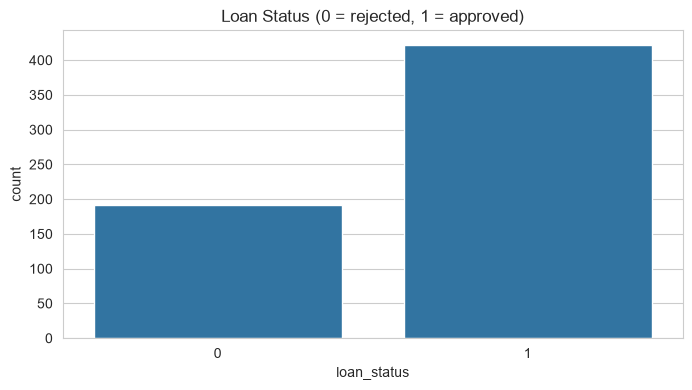

In [47]:
# Is the target balanced?
sns.countplot(data=df, x="loan_status")
plt.title("Loan Status (0 = rejected, 1 = approved)")
plt.show()

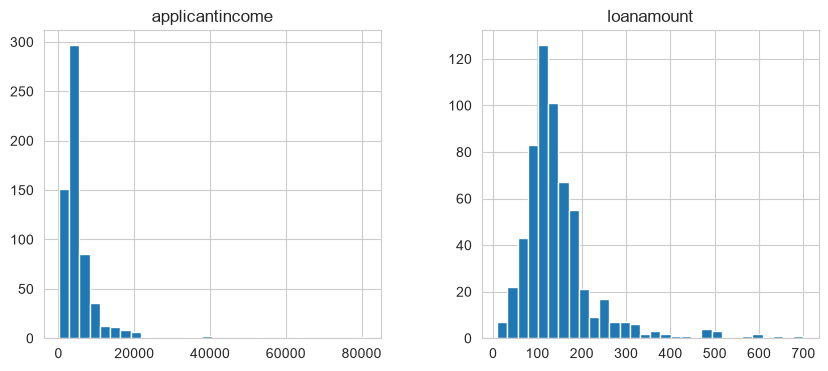

In [48]:
# Distribution of the numeric columns
df[["applicantincome", "loanamount"]].hist(bins=30, figsize=(10, 4))
plt.show()

**What I see:** Both distributions are right-skewed, with most observations at lower values and a smaller number of high-income or high-loan-amount observations.

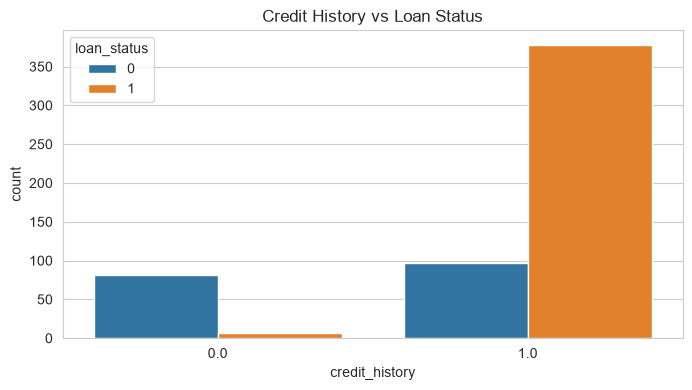

In [49]:
# Credit history vs loan status
sns.countplot(data=df, x="credit_history", hue="loan_status")
plt.title("Credit History vs Loan Status")
plt.show()

**What I see:** This is the clearest chart. Most applicants with `credit_history = 0` were rejected, showing a strong association between credit history and the observed approval decision.

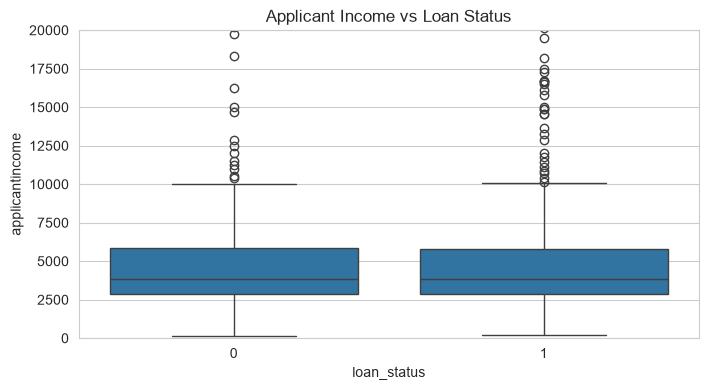

In [50]:
# Income for approved vs rejected
sns.boxplot(data=df, x="loan_status", y="applicantincome")
plt.ylim(0, 20000)
plt.title("Applicant Income vs Loan Status")
plt.show()

**What I see:** The applicant-income distributions overlap substantially between approved and rejected groups. In this sample, income alone does not clearly separate the two historical outcome groups. This does not mean income is irrelevant in every lending context.

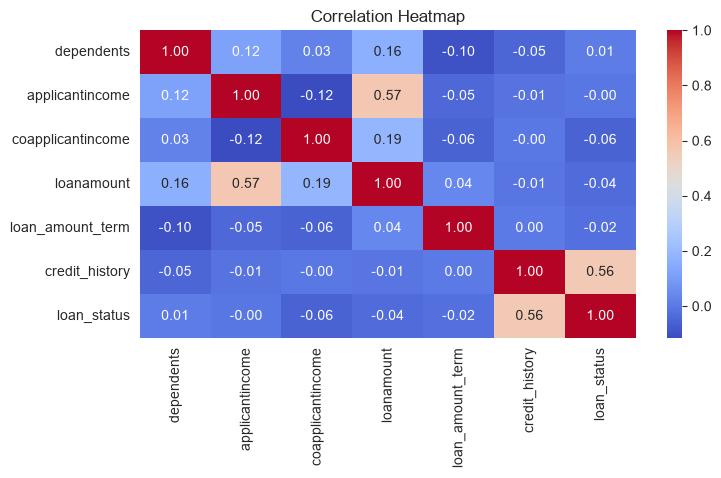

In [51]:
# Correlation heatmap
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

**What I see:** `credit_history` has the strongest observed correlation with `loan_status` among the numeric variables displayed (about 0.56). Applicant income and loan amount are also positively correlated (about 0.57). Correlation describes association, not causation, and these values do not by themselves establish predictive importance.

---
## 6. Prepare the Data for Modelling

**The rule:** anything that *learns* something from the data (the fill values for missing data, the list of
categories, the scaling) must be learned from the **training set only**. scikit-learn tools follow one simple pattern:

> **fit on the training set → transform the training set → transform the test set**

A `Pipeline` chains these steps together and does this automatically, every time — including inside cross-validation.
A `ColumnTransformer` lets us give each group of columns its own treatment.

Steps:
1. Create one new feature: `total_income` (applicant + co-applicant). It only uses numbers from the same row, so it is safe before the split.
2. Split into train and test.
3. Build the preprocessor: fill missing values and one-hot encode.
4. See the fit → transform pattern in action.

In [52]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. New feature: the household income, not just one person
df["total_income"] = df["applicantincome"] + df["coapplicantincome"]

# 2. Split BEFORE anything is learned from the data
X = df.drop(columns=["loan_status"])   # features
y = df["loan_status"]                  # target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set    :", X_test.shape)
print("Approval rate  train:", round(y_train.mean(), 4), "  test:", round(y_test.mean(), 4))
print("Missing values  train:", X_train.isnull().sum().sum(), "  test:", X_test.isnull().sum().sum(), "(still there, not filled yet)")

Training set: (491, 12)
Test set    : (123, 12)
Approval rate  train: 0.6864   test: 0.6911
Missing values  train: 124   test: 25 (still there, not filled yet)


**Why `stratify=y`?** Stratification keeps the approval/rejection proportions approximately consistent between the training and test sets. The held-out test set is reserved for final evaluation. All preprocessing that learns values or categories is placed inside pipelines so it is fitted on the training data, not on the test data.

In [69]:
# 3. The preprocessor: what to do with each group of columns
text_cols = ["gender", "married", "education", "self_employed", "property_area"]

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            # numbers -> fill missing values with the MEDIAN (safer than the mean because of outliers)
            ("median", SimpleImputer(strategy="median"), ["loanamount", "loan_amount_term"]),

            # whole numbers / 0-1 flags -> fill with the MOST COMMON value
            ("mode_num", SimpleImputer(strategy="most_frequent"), ["dependents", "credit_history"]),

            # text columns -> fill with the most common value, then one-hot encode
            ("text", Pipeline([
                ("fill", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
            ]), text_cols),

            # income columns have no missing values -> keep as they are
            ("keep", "passthrough", ["applicantincome", "coapplicantincome", "total_income"]),
        ],
        verbose_feature_names_out=False,)

print("Preprocessor defined.")

Preprocessor defined.


In [54]:
# 4. The pattern in action: fit on TRAIN, transform TRAIN, transform TEST
preprocessor = make_preprocessor()
preprocessor.fit(X_train)                        # learns the fill values + categories from the TRAINING set only
X_train_prep = preprocessor.transform(X_train)   # applied to the training set
X_test_prep = preprocessor.transform(X_test)     # applied to the test set, using the values learned from training

names = preprocessor.get_feature_names_out()
print("Columns after preprocessing:", len(names))
print("Missing values left  train:", int(np.isnan(X_train_prep).sum()), "  test:", int(np.isnan(X_test_prep).sum()))
print()
print("Fill values learned from the TRAINING set:")
print("  median of loanamount, loan_amount_term :", preprocessor.named_transformers_["median"].statistics_)
print("  most common dependents, credit_history :", preprocessor.named_transformers_["mode_num"].statistics_)

pd.DataFrame(X_train_prep, columns=names).head()

Columns after preprocessing: 13
Missing values left  train: 0   test: 0

Fill values learned from the TRAINING set:
  median of loanamount, loan_amount_term : [128. 360.]
  most common dependents, credit_history : [0. 1.]


,loanamount,loan_amount_term,dependents,credit_history,gender_male,married_yes,education_not graduate,self_employed_yes,property_area_semiurban,property_area_urban,applicantincome,coapplicantincome,total_income
0,50.0,360.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,3254.0,0.0,3254.0
1,96.0,360.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,3315.0,0.0,3315.0
2,150.0,360.0,2.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,3340.0,1710.0,5050.0
3,113.0,180.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,2653.0,1500.0,4153.0
4,150.0,360.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,2620.0,2223.0,4843.0


**What just happened:** the fill values (e.g. the median loan amount, 128) were calculated from the 491 training
applications only. The test applications were then filled with those same values — the test set never had any say.

From now on, each model is a `Pipeline` = **preprocessor → (scaler) → model**. When we call `.fit(X_train, y_train)`
the whole chain is fitted on the training set, and `.predict(X_test)` applies it to new data.

**Why scaling?** KNN measures distance between applicants. Without scaling, `applicantincome`
(thousands) would be much bigger than `dependents` (0–3), so income would control everything.
Logistic Regression also works better when scaled. Decision Tree does not need it, so its pipeline has no scaler.

---
## 7. Model 1 — Logistic Regression

This is the simplest classification model. It draws a straight line between the two classes.

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

log_model = Pipeline([
    ("prep", make_preprocessor()),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
log_model.fit(X_train, y_train)

log_pred = log_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, log_pred), 4))
print()
print(classification_report(y_test, log_pred))

Accuracy: 0.8618

              precision    recall  f1-score   support

           0       0.96      0.58      0.72        38
           1       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



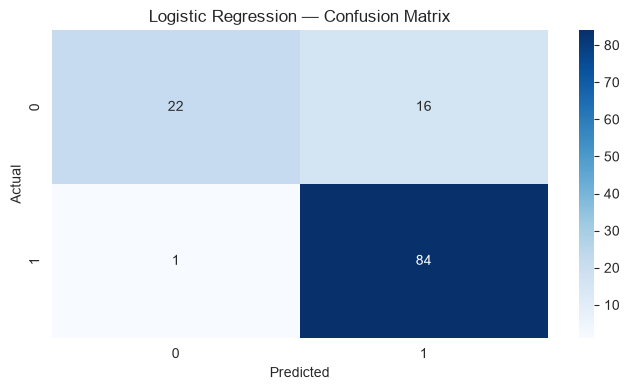

In [56]:
sns.heatmap(confusion_matrix(y_test, log_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Result:** Logistic Regression achieved 86.18% accuracy on the held-out test set. For the approved class, it identified 84 of 85 approved applications (recall 98.82%). For the rejected class, it identified 22 of 38 rejected applications (recall 57.89%) and incorrectly predicted approval for 16 rejected applications. These class-specific errors matter more than accuracy alone in a lending context.

This model learns a sequence of decision rules. I set `max_depth=4` in advance to keep the tree relatively small and interpretable. This depth was **not** selected through cross-validation; the report and README explicitly describe that choice so the methodology is represented accurately.

In [57]:
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline([
    ("prep", make_preprocessor()),                                   # no scaler: a tree does not need it
    ("model", DecisionTreeClassifier(max_depth=4, random_state=42)),
])
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, tree_pred), 4))
print()
print(classification_report(y_test, tree_pred))

Accuracy: 0.8455

              precision    recall  f1-score   support

           0       0.91      0.55      0.69        38
           1       0.83      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.87      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123



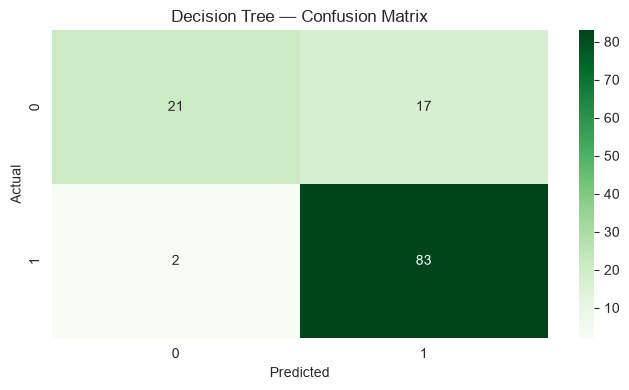

In [58]:
sns.heatmap(confusion_matrix(y_test, tree_pred), annot=True, fmt="d", cmap="Greens")
plt.title("Decision Tree — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

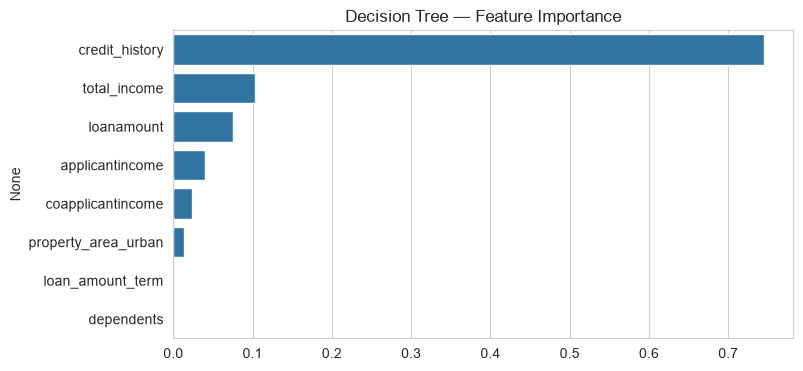

credit_history         0.7448
total_income           0.1025
loanamount             0.0757
applicantincome        0.0401
coapplicantincome      0.0234
property_area_urban    0.0135
loan_amount_term       0.0000
dependents             0.0000
dtype: float64


In [59]:
# Which features did the tree use?
feature_names = tree_model.named_steps["prep"].get_feature_names_out()
importance = pd.Series(tree_model.named_steps["model"].feature_importances_, index=feature_names)
importance = importance.sort_values(ascending=False).head(8)

sns.barplot(x=importance.values, y=importance.index)
plt.title("Decision Tree — Feature Importance")
plt.show()

print(importance.round(4))

**Result:** The Decision Tree achieved 84.55% accuracy on the held-out test set, slightly below Logistic Regression. The feature-importance output assigns the largest importance to `credit_history` (about 0.7448). Feature importance is model-specific and should not be interpreted as causal impact.

This model classifies an applicant based on nearby training examples.

**How is k chosen?** I compare odd values of `k` from 1 to 29 using 5-fold stratified cross-validation on the training set only. The selection criterion is **mean cross-validation accuracy**. Because preprocessing and scaling are inside the pipeline, they are refitted within each cross-validation fold. The held-out test set is not used to choose `k`.

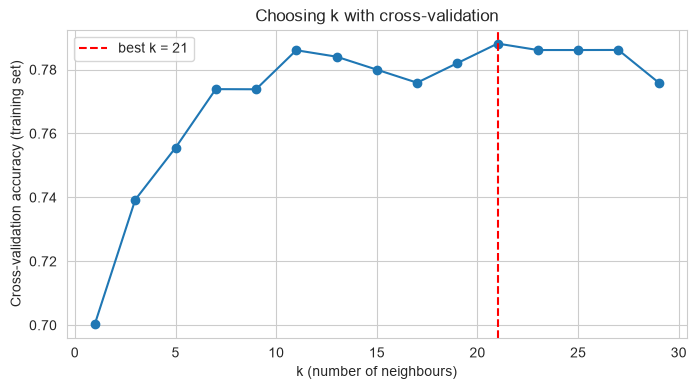

Best k (chosen with cross-validation on the training set): 21
Cross-validation accuracy at best k: 0.7881


In [60]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = list(range(1, 31, 2))
cv_scores = []

# Try each k using the TRAINING set only
for k in k_values:
    knn = Pipeline([
        ("prep", make_preprocessor()),
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k)),
    ])
    score = cross_val_score(knn, X_train, y_train, cv=cv, scoring="accuracy").mean()
    cv_scores.append(score)

best_k = k_values[int(np.argmax(cv_scores))]

plt.plot(k_values, cv_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"best k = {best_k}")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validation accuracy (training set)")
plt.title("Choosing k with cross-validation")
plt.legend()
plt.show()

print("Best k (chosen with cross-validation on the training set):", best_k)
print("Cross-validation accuracy at best k:", round(max(cv_scores), 4))

**What I see:** In the saved run, cross-validation selected `k = 21`. This is a result of the current training split and dataset version, not a universal best value. The final KNN pipeline uses that selected value.

In [61]:
# Train the final KNN with the k found above (no number typed by hand)
knn_model = Pipeline([
    ("prep", make_preprocessor()),
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=best_k)),
])
knn_model.fit(X_train, y_train)

# First time the test set is used for KNN
knn_pred = knn_model.predict(X_test)

print("k used:", best_k)
print("Accuracy:", round(accuracy_score(y_test, knn_pred), 4))
print()
print(classification_report(y_test, knn_pred))

k used: 21
Accuracy: 0.813

              precision    recall  f1-score   support

           0       0.94      0.42      0.58        38
           1       0.79      0.99      0.88        85

    accuracy                           0.81       123
   macro avg       0.87      0.70      0.73       123
weighted avg       0.84      0.81      0.79       123



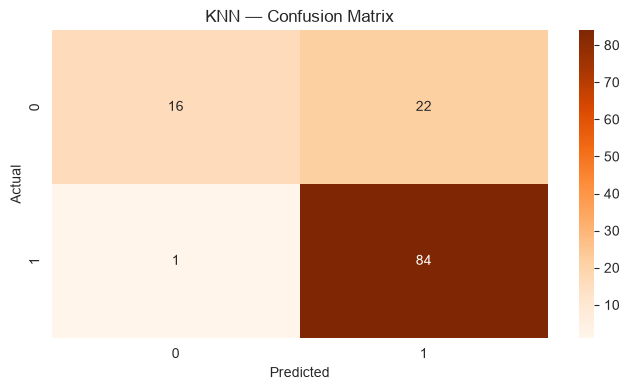

In [62]:
sns.heatmap(confusion_matrix(y_test, knn_pred), annot=True, fmt="d", cmap="Oranges")
plt.title("KNN — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Result:** KNN achieved 81.30% accuracy on the held-out test set with `k = 21`. It identified 16 of 38 rejected applications (recall 42.11%) and incorrectly predicted approval for 22 rejected applications. The model also identified 84 of 85 approved applications. This shows why class-specific metrics and the confusion matrix are essential.

---
## 10. Evaluate

The test set has been used **once for each model** — only for the final score, never to make a choice.

Before judging the models, I need a baseline: what if we just approve everybody?

In [63]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Baseline: say "approved" to everyone
baseline_pred = np.ones(len(y_test))

print("BASELINE (approve everyone)")
print("  Accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("  F1-score:", round(f1_score(y_test, baseline_pred), 4))

BASELINE (approve everyone)
  Accuracy: 0.6911
  F1-score: 0.8173


**Baseline interpretation:** Predicting “approved” for every application achieves 69.11% accuracy because about 69% of the test applications were approved. The trained models score higher on overall accuracy, but their errors—especially incorrectly predicting approval for rejected applications—must still be assessed carefully.

---
## 11. Compare the Models

In [64]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "KNN", "Baseline (approve all)"],
    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, baseline_pred),
    ],
    "Precision": [
        precision_score(y_test, log_pred),
        precision_score(y_test, tree_pred),
        precision_score(y_test, knn_pred),
        precision_score(y_test, baseline_pred),
    ],
    "Recall": [
        recall_score(y_test, log_pred),
        recall_score(y_test, tree_pred),
        recall_score(y_test, knn_pred),
        recall_score(y_test, baseline_pred),
    ],
    "F1-score": [
        f1_score(y_test, log_pred),
        f1_score(y_test, tree_pred),
        f1_score(y_test, knn_pred),
        f1_score(y_test, baseline_pred),
    ],
}).round(4)

results

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8618,0.8400,0.9882,0.9081
1,Decision Tree,0.8455,0.8300,0.9765,0.8973
2,KNN,0.8130,0.7925,0.9882,0.8796
3,Baseline (approve all),0.6911,0.6911,1.0000,0.8173


In [65]:
# Save the comparison table (this is one of the deliverables)
results.to_csv("model_comparison_table.csv", index=False)
print("Saved: model_comparison_table.csv")

Saved: model_comparison_table.csv


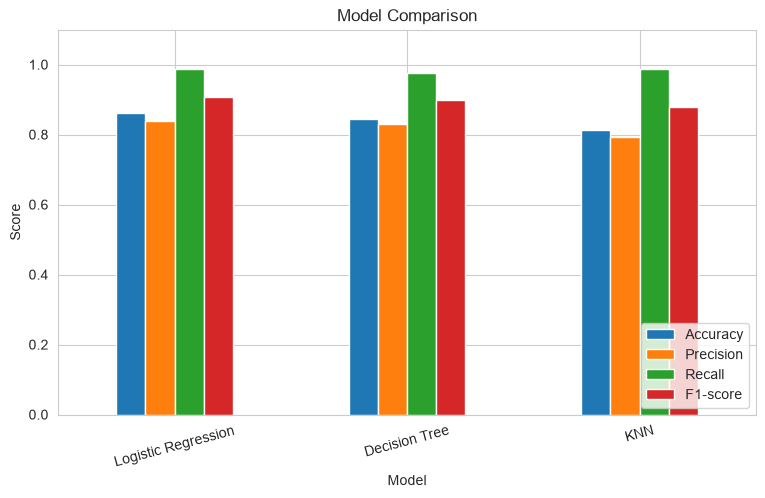

In [66]:
# Chart the comparison
chart_data = results[results["Model"] != "Baseline (approve all)"]
chart_data.set_index("Model").plot(kind="bar", figsize=(9, 5), rot=15)
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.legend(loc="lower right")
plt.show()

**Model comparison:** Logistic Regression has the highest recorded accuracy (86.18%) and F1-score for the approved class (0.9081) among these three models on this test split. The Decision Tree is close behind at 84.55% accuracy; KNN scores 81.30%.

For this educational comparison, Logistic Regression is the best-performing model by the reported overall accuracy and approved-class F1-score. However, it identifies only 22 of 38 rejected applications. This result is not sufficient to recommend automated use in real lending decisions.

## Main findings

1. **Credit history is the strongest observed signal in this analysis.** The descriptive approval rate was 79.6% for applications with a recorded good credit history and 7.9% for those with a recorded value of 0. Missing values were imputed with the most frequent training-set value for modeling, which may affect results.
2. **Applicant income alone does not clearly separate the two outcome groups.** The distributions overlap substantially in this dataset.
3. **Logistic Regression performed best on the recorded overall test metrics.** It achieved 86.18% accuracy and an approved-class F1-score of 0.9081.
4. **The error pattern remains important.** Logistic Regression incorrectly predicted approval for 16 of 38 applications that were actually rejected in the test set.
5. **The dataset reflects historical decisions, not loan repayment.** The model learns patterns in prior decisions and may reproduce historical bias.

## Limitations and responsible use

- The dataset is small (614 applications; 123 held out for testing) and moderately imbalanced.
- There are 149 missing cells across the original dataset; 134 rows have at least one missing value.
- `credit_history` is both highly predictive in this dataset and has 50 missing values. Imputing its missing values with the most frequent training-set value is a strong assumption.
- The target is historical approval (`Y`/`N`), not repayment or default.
- Gender and marital status are included as predictors. Fairness and subgroup error rates would need careful evaluation before any real-world use.
- The Logistic Regression and KNN pipelines use training-only preprocessing. KNN's `k` is selected using 5-fold training-set cross-validation by accuracy; the Decision Tree depth (`max_depth=4`) is specified in advance rather than cross-validated.
- Results should be reproduced from the exact dataset version before publication.

## Conclusion

The three models outperform the approve-all accuracy baseline on this particular split. Logistic Regression has the highest recorded accuracy and approved-class F1-score, but it misses 16 of the 38 rejected applications. The project demonstrates a practical classification workflow and the importance of data cleaning, leakage-safe preprocessing, evaluation beyond accuracy, and transparent limitations.

> **This is an educational portfolio project only. It is not suitable for automated loan approval or rejection without substantial further validation, fairness assessment, governance, and human oversight.**

## Reflection

The most important lesson was that a model can run without errors while still producing misleading results if data preparation or model selection allows information to leak from the evaluation data. Using pipelines and training-only cross-validation makes the evaluation more defensible. I also learned to report findings that challenge expectations—such as the weak separation in applicant income—rather than forcing the data to support an assumption.

— **Abdulkadir Abdullahi Mohamed**
